<a href="https://colab.research.google.com/github/abelfernando/acesso_ensino_superior_2006a2024/blob/main/Acesso_Ensino_Superior_2006_a_2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Histórica de Matrículas no Ensino Superior Brasileiro (2006–2024)

### Expansão por Grau Acadêmico (Bacharelado, Licenciatura e Tecnológico) e Dependência Administrativa (Pública vs. Privada)

---

## 1. Sobre este Notebook

Este notebook implementa um pipeline reprodutível de extração, tratamento, modelagem e visualização de dados para analisar a dinâmica de matrículas no Ensino Superior no Brasil entre **2006 e 2024**.

### Objetivos Analíticos
* **Evolução Temporal Completa (2006–2024):** Avaliar o comportamento das matrículas antes e depois do marco legal de 2008 (criação dos Institutos Federais pela Lei nº 11.892/2008).
* **Segmentação por Grau e Rede:** Comparar o ritmo de expansão nos três graus acadêmicos (**Bacharelado**, **Licenciatura** e **Tecnológico**) entre as redes **Pública** e **Privada**.
* **Indicadores:** Matrículas absolutas, crescimento ano a ano (YoY %), CAGR acumulado e participação relativa de mercado (*market share*).

### Metodologia e Fontes de Dados
1. **2009 a 2024:** Extração direta via **Google BigQuery** consumindo a tabela harmonizada `basedosdados.br_inep_censo_educacao_superior.curso`.
2. **2006 a 2008:** Ingestão dos microdados brutos do Censo da Educação Superior do **INEP** (`Graduacao_Presencial.csv` e `Graduacao_distancia.csv`), harmonizando as categorias administrativas (`CATEGADM`), as variáveis indicadoras de grau (`EH_BACHARI`, `EH_LICENCPLENA`, `EH_TECNO`) e a soma das matrículas do 1º semestre (conforme os gabaritos oficiais do Censo).

In [ ]:
!pip install basedosdados -q

In [ ]:
import basedosdados as bd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from google.colab import userdata

# Recupera o ID do projeto armazenado no Secrets do Colab
PROJECT_ID = userdata.get("GCP_PROJECT_ID")

In [ ]:
# Consulta SQL com tratamento para anomalia do campo 'rede' em 2013
query_harmonizada = """
SELECT
    ano,
    tipo_grau_academico,
    CASE
        WHEN CAST(rede AS STRING) = '1' THEN 'Pública'
        WHEN CAST(rede AS STRING) = '2' THEN 'Privada'
        WHEN CAST(tipo_organizacao_administrativa AS STRING) IN ('1', '2', '3') THEN 'Pública'
        WHEN CAST(tipo_organizacao_administrativa AS STRING) IN ('4', '5', '6', '7') THEN 'Privada'
        ELSE NULL
    END AS rede,
    SUM(quantidade_matriculas) AS total_matriculas
FROM `basedosdados.br_inep_censo_educacao_superior.curso`
WHERE ano BETWEEN 2009 AND 2024
  AND tipo_grau_academico IN ('1', '2', '3', '4')
GROUP BY
    ano,
    tipo_grau_academico,
    rede
HAVING rede IS NOT NULL
ORDER BY
    ano,
    rede,
    tipo_grau_academico
"""

print("Executando consulta no BigQuery (2009–2024)...")
df_harm_raw = bd.read_sql(query_harmonizada, billing_project_id=PROJECT_ID)

# Mapeamento dos graus (Bacharelado inclui código 1 e 4)
mapa_graus = {
    '1': 'Bacharelado',
    '4': 'Bacharelado',
    '2': 'Licenciatura',
    '3': 'Tecnológico'
}

df_harm = df_harm_raw.copy()
df_harm['grau'] = df_harm['tipo_grau_academico'].map(mapa_graus)
df_harm = df_harm[['ano', 'rede', 'grau', 'total_matriculas']]

print(f"Dados pós-2009 extraídos com sucesso: {df_harm['total_matriculas'].sum():,} matrículas computadas.")

Executando consulta no BigQuery (2009–2024)...
Downloading: 100%|██████████|
Dados pós-2009 extraídos com sucesso: 129,515,936 matrículas computadas.


## 2. Ingestão e Harmonização dos Microdados do INEP (2006 a 2008)

Os dados anteriores a 2009 utilizam a estrutura posicional/matricial do questionário do Censo. A função abaixo processa os arquivos locais `Graduacao_Presencial.csv` e `Graduacao_distancia` de cada ano e padroniza para o mesmo esquema tabular do BigQuery (`ano`, `rede`, `grau`, `total_matriculas`).

In [ ]:
import os
import glob
import pandas as pd

def processar_censo_pre_2009(caminho_csv, ano, colunas_matricula):
    """
    Processa arquivos brutos do INEP (2006 a 2008) detectando automaticamente
    o delimitador ('|' ou ';') e padronizando para o schema:
    ['ano', 'rede', 'grau', 'total_matriculas'].
    """
    # 1. Detecção automática do delimitador inspecionando a primeira linha
    with open(caminho_csv, 'r', encoding='latin1', errors='ignore') as f:
        primeira_linha = f.readline()

    delimitadores = ['|', ';', ',']
    sep_detectado = max(delimitadores, key=lambda d: primeira_linha.count(d))

    # 2. Leitura com o delimitador correto
    df = pd.read_csv(
        caminho_csv,
        sep=sep_detectado,
        encoding='latin1',
        low_memory=False,
        on_bad_lines='skip'
    )

    # 3. Padroniza nomes de colunas em maiúsculas
    df.columns = df.columns.str.upper().str.strip()

    # 4. Identificação da Rede (Pública vs Privada)
    col_rede = 'CATEGADM' if 'CATEGADM' in df.columns else 'CATADM'
    df['rede_normalizada'] = df[col_rede].astype(str).str.strip().str.title()

    mapa_rede = {
        'Pública': 'Pública', 'Publica': 'Pública',
        'Federal': 'Pública', 'Estadual': 'Pública', 'Municipal': 'Pública',
        'Privada': 'Privada', 'Particular': 'Privada',
        'Comunitária': 'Privada', 'Confessional': 'Privada', 'Filantrópica': 'Privada'
    }
    df['rede_normalizada'] = df['rede_normalizada'].map(mapa_rede)

    # 5. Identificação do Grau Acadêmico via variáveis booleanas (EH_*)
    def extrair_grau(row):
        for c in ['EH_TECNO', 'EHTECNO']:
            if c in row and str(row[c]).strip().upper() in ['1', 'S', 'TRUE']:
                return 'Tecnológico'
        for c in ['EH_LICENCPLENA', 'EH_LICCURTA', 'EHLICENCPLENA']:
            if c in row and str(row[c]).strip().upper() in ['1', 'S', 'TRUE']:
                return 'Licenciatura'
        for c in ['EH_BACHARI', 'EH_BACHARELADO', 'EHBACHARI']:
            if c in row and str(row[c]).strip().upper() in ['1', 'S', 'TRUE']:
                return 'Bacharelado'
        return None

    df['grau_normalizado'] = df.apply(extrair_grau, axis=1)

    # 6. Totalização das matrículas do 1º semestre
    cols_existentes = [c.upper() for c in colunas_matricula if c.upper() in df.columns]
    df['total_matriculas'] = df[cols_existentes].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)

    # 7. Agregação no formato padronizado
    df_valido = df[df['rede_normalizada'].notna() & df['grau_normalizado'].notna()].copy()
    df_agr = df_valido.groupby(['rede_normalizada', 'grau_normalizado'])['total_matriculas'].sum().reset_index()
    df_agr.rename(columns={'rede_normalizada': 'rede', 'grau_normalizado': 'grau'}, inplace=True)
    df_agr['ano'] = ano

    return df_agr[['ano', 'rede', 'grau', 'total_matriculas']]

In [ ]:
# Mapeamento unificado das colunas de matrícula do 1º semestre
# Presencial (2006, 2007 e 2008 compartilham as mesmas colunas C0421 a C0424)
colunas_matr_presencial = ['C0421', 'C0422', 'C0423', 'C0424']

# EaD (2006 usa C2011/12; 2007 e 2008 usam C167011/12)
colunas_matr_ead_2006 = ['C2011', 'C2012']
colunas_matr_ead_2007_2008 = ['C167011', 'C167012']

# Configuração de todos os arquivos locais pré-2009 (Presencial + EaD)
arquivos_config = [
    # 2006
    ('/content/GRADUACAO_PRESENCIAL_2006.CSV', 2006, colunas_matr_presencial),
    ('/content/GRADUACAO_DISTANCIA_2006.CSV',  2006, colunas_matr_ead_2006),
    # 2007
    ('/content/GRADUACAO_PRESENCIAL_2007.CSV', 2007, colunas_matr_presencial),
    ('/content/GRADUACAO_DISTANCIA_2007.CSV',  2007, colunas_matr_ead_2007_2008),
    # 2008
    ('/content/GRADUACAO_PRESENCIAL_2008.CSV', 2008, colunas_matr_presencial),
    ('/content/GRADUACAO_DISTANCIA_2008.CSV',  2008, colunas_matr_ead_2007_2008)
]

dfs_pre_2009 = []
for caminho, ano, colunas in arquivos_config:
    if os.path.exists(caminho):
        df_ano = processar_censo_pre_2009(caminho, ano, colunas)
        dfs_pre_2009.append(df_ano)
        print(f"Microdado carregado: {os.path.basename(caminho)} ({ano}) -> {df_ano['total_matriculas'].sum():,} alunos")
    else:
        print(f"Arquivo não encontrado: {caminho}")

# Concatenação com a série 2009-2024 do BigQuery
if dfs_pre_2009:
    df_consolidado = pd.concat(dfs_pre_2009 + [df_harm], ignore_index=True)
    print(f"\nSérie histórica unificada: {df_consolidado['ano'].min()} a {df_consolidado['ano'].max()}.")
else:
    df_consolidado = df_harm.copy()
    print("\nNenhum arquivo pré-2009 encontrado localmente. Utilizando série 2009 a 2024.")

Microdado carregado: GRADUACAO_PRESENCIAL_2006.CSV (2006) -> 4,288,430.0 alunos
Microdado carregado: GRADUACAO_DISTANCIA_2006.CSV (2006) -> 206,759.0 alunos
Microdado carregado: GRADUACAO_PRESENCIAL_2007.CSV (2007) -> 4,473,342.0 alunos
Microdado carregado: GRADUACAO_DISTANCIA_2007.CSV (2007) -> 369,658.0 alunos
Microdado carregado: GRADUACAO_PRESENCIAL_2008.CSV (2008) -> 4,661,425.0 alunos
Microdado carregado: GRADUACAO_DISTANCIA_2008.CSV (2008) -> 727,846.0 alunos

Série histórica unificada: 2006 a 2024.


In [ ]:
# Pivotagem multidimensional (Ano nas linhas, Rede x Grau nas colunas)
df_pivot_final = df_consolidado.pivot_table(
    index='ano',
    columns=['rede', 'grau'],
    values='total_matriculas',
    aggfunc='sum'
).fillna(0).astype(int)

# Subtotais por rede e total Brasil
for r in ['Pública', 'Privada']:
    if r in df_pivot_final.columns.levels[0]:
        df_pivot_final[(r, 'Total')] = df_pivot_final[r].sum(axis=1)

df_pivot_final[('Geral', 'Total_Brasil')] = (
    df_pivot_final[('Pública', 'Total')] + df_pivot_final[('Privada', 'Total')]
)

df_pivot_final = df_pivot_final.sort_index(axis=1)

print("=== SÉRIE HISTÓRICA CONSOLIDADA DE MATRÍCULAS ===")
display(df_pivot_final)

=== SÉRIE HISTÓRICA CONSOLIDADA DE MATRÍCULAS ===


rede        Geral     Privada                                       Pública  \
grau Total_Brasil Bacharelado Licenciatura Tecnológico    Total Bacharelado   
ano                                                                           
2006      4495189     2329554       820046      262997  3412597      455059   
2007      4843000     2492695       843674      350002  3686371      527632   
2008      5389271     2691330       881878      448360  4021568      665516   
2009      5954021     3118373       732995      578789  4430157      963206   
2010      6363315     3276792       793268      665886  4735946      949925   
2011      6722694     3456292       768000      742001  4966293     1039539   
2012      7015156     3573916       762076      803969  5139961     1129777   
2013      7282230     3848555       791213      864568  5504336     1063755   
2014      7805727     4117218       862012      887478  5866708     1192194   
2015      7998223     4321131       892933      860933  6074997     1195020   
2016      8016459     4327767       941380      789229  6058376     1221969   
2017      8251080     4417876       987601      835625  6241102     1244475   
2018      8416077     4427356      1016249      929540  6373145     1261979   
2019      8574157     4393300      1079114     1050830  6523244     1269639   
2020      8658565     4349509      1105166     1268562  6723237     1210178   
2021      8958647     4395940      1060954     1449088  6905982     1295533   
2022      9405593     4610214      1097982     1647646  7355842     1311894   
2023      9928172     4884343      1148576     1851898  7884817     1302610   
2024     10165820     5091908      1163808     1874521  8130237     1300885   

rede                                    
grau Licenciatura Tecnológico    Total  
ano                                     
2006       564629       62904  1082592  
2007       564177       64820  1156629  
2008       610896       91291  1367703  
2009       458768      101890  1523864  
2010       561721      115723  1627369  
2011       588329      128533  1756401  
2012       604483      140935  1875195  
2013       582961      131178  1777894  
2014       604536      142289  1939019  
2015       578997      149209  1923226  
2016       579114      157000  1958083  
2017       601839      163664  2009978  
2018       612427      168526  2042932  
2019       608253      173021  2050913  
2020       558515      166635  1935328  
2021       587374      169758  2052665  
2022       571929      165928  2049751  
2023       562407      178338  2043355  
2024       554782      179916  2035583

In [ ]:
# 1. Identificação dinâmica do recorte temporal
ano_inicio = df_pivot_final.index.min()
ano_fim = df_pivot_final.index.max()
periodo_anos = ano_fim - ano_inicio

val_inicio = df_pivot_final.loc[ano_inicio]
val_fim = df_pivot_final.loc[ano_fim]

# 2. Crescimento Acumulado e CAGR
crescimento_acumulado = ((val_fim - val_inicio) / val_inicio) * 100
cagr = (((val_fim / val_inicio) ** (1 / periodo_anos)) - 1) * 100

df_resumo_crescimento = pd.DataFrame({
    f"Matrículas {ano_inicio}": val_inicio,
    f"Matrículas {ano_fim}": val_fim,
    "Variação Absoluta": val_fim - val_inicio,
    "Crescimento Total (%)": crescimento_acumulado.round(2),
    "CAGR a.a. (%)": cagr.round(2)
})

# 3. Market Share (Participação Pública vs. Privada por Grau)
df_market_share = pd.DataFrame(index=df_pivot_final.index)
for grau in ['Bacharelado', 'Licenciatura', 'Tecnológico', 'Total']:
    col_priv = ('Privada', grau)
    col_pub = ('Pública', grau)
    total_grau = df_pivot_final[col_priv] + df_pivot_final[col_pub]

    df_market_share[(grau, '% Privada')] = ((df_pivot_final[col_priv] / total_grau) * 100).round(2)
    df_market_share[(grau, '% Pública')] = ((df_pivot_final[col_pub] / total_grau) * 100).round(2)

df_market_share.columns = pd.MultiIndex.from_tuples(df_market_share.columns, names=['grau', 'rede'])
df_market_share = df_market_share.sort_index(axis=1)

# 4. Crescimento Anual (YoY %)
df_yoy = (df_pivot_final.pct_change() * 100).round(2)

print(f"=== 1. RESUMO: CAGR E EXPANSÃO ({ano_inicio} - {ano_fim}) ===")
display(df_resumo_crescimento)

print("\n=== 2. DIVISÃO DE MERCADO (% SHARE POR GRAU) ===")
display(df_market_share)

print("\n=== 3. CRESCIMENTO ANO A ANO (% YoY) ===")
display(df_yoy.dropna())

=== 1. RESUMO: CAGR E EXPANSÃO (2006 - 2024) ===


Matrículas 2006  Matrículas 2024  Variação Absoluta  \
rede    grau                                                                
Geral   Total_Brasil          4495189         10165820            5670631   
Privada Bacharelado           2329554          5091908            2762354   
        Licenciatura           820046          1163808             343762   
        Tecnológico            262997          1874521            1611524   
        Total                 3412597          8130237            4717640   
Pública Bacharelado            455059          1300885             845826   
        Licenciatura           564629           554782              -9847   
        Tecnológico             62904           179916             117012   
        Total                 1082592          2035583             952991   

                      Crescimento Total (%)  CAGR a.a. (%)  
rede    grau                                                
Geral   Total_Brasil                 126.15           4.64  
Privada Bacharelado                  118.58           4.44  
        Licenciatura                  41.92           1.96  
        Tecnológico                  612.75          11.53  
        Total                        138.24           4.94  
Pública Bacharelado                  185.87           6.01  
        Licenciatura                  -1.74          -0.10  
        Tecnológico                  186.02           6.01  
        Total                         88.03           3.57


=== 2. DIVISÃO DE MERCADO (% SHARE POR GRAU) ===


grau Bacharelado           Licenciatura           Tecnológico            \
rede   % Privada % Pública    % Privada % Pública   % Privada % Pública   
ano                                                                       
2006       83.66     16.34        59.22     40.78       80.70     19.30   
2007       82.53     17.47        59.93     40.07       84.37     15.63   
2008       80.17     19.83        59.08     40.92       83.08     16.92   
2009       76.40     23.60        61.51     38.49       85.03     14.97   
2010       77.53     22.47        58.54     41.46       85.19     14.81   
2011       76.88     23.12        56.62     43.38       85.24     14.76   
2012       75.98     24.02        55.77     44.23       85.08     14.92   
2013       78.35     21.65        57.58     42.42       86.83     13.17   
2014       77.55     22.45        58.78     41.22       86.18     13.82   
2015       78.34     21.66        60.66     39.34       85.23     14.77   
2016       77.98     22.02        61.91     38.09       83.41     16.59   
2017       78.02     21.98        62.14     37.86       83.62     16.38   
2018       77.82     22.18        62.40     37.60       84.65     15.35   
2019       77.58     22.42        63.95     36.05       85.86     14.14   
2020       78.23     21.77        66.43     33.57       88.39     11.61   
2021       77.24     22.76        64.37     35.63       89.51     10.49   
2022       77.85     22.15        65.75     34.25       90.85      9.15   
2023       78.95     21.05        67.13     32.87       91.22      8.78   
2024       79.65     20.35        67.72     32.28       91.24      8.76   

grau     Total            
rede % Privada % Pública  
ano                       
2006     75.92     24.08  
2007     76.12     23.88  
2008     74.62     25.38  
2009     74.41     25.59  
2010     74.43     25.57  
2011     73.87     26.13  
2012     73.27     26.73  
2013     75.59     24.41  
2014     75.16     24.84  
2015     75.95     24.05  
2016     75.57     24.43  
2017     75.64     24.36  
2018     75.73     24.27  
2019     76.08     23.92  
2020     77.65     22.35  
2021     77.09     22.91  
2022     78.21     21.79  
2023     79.42     20.58  
2024     79.98     20.02


=== 3. CRESCIMENTO ANO A ANO (% YoY) ===


rede        Geral     Privada                                     Pública  \
grau Total_Brasil Bacharelado Licenciatura Tecnológico  Total Bacharelado   
ano                                                                         
2007         7.74        7.00         2.88       33.08   8.02       15.95   
2008        11.28        7.97         4.53       28.10   9.09       26.13   
2009        10.48       15.87       -16.88       29.09  10.16       44.73   
2010         6.87        5.08         8.22       15.05   6.90       -1.38   
2011         5.65        5.48        -3.19       11.43   4.86        9.43   
2012         4.35        3.40        -0.77        8.35   3.50        8.68   
2013         3.81        7.68         3.82        7.54   7.09       -5.84   
2014         7.19        6.98         8.95        2.65   6.58       12.07   
2015         2.47        4.95         3.59       -2.99   3.55        0.24   
2016         0.23        0.15         5.43       -8.33  -0.27        2.26   
2017         2.93        2.08         4.91        5.88   3.02        1.84   
2018         2.00        0.21         2.90       11.24   2.12        1.41   
2019         1.88       -0.77         6.19       13.05   2.36        0.61   
2020         0.98       -1.00         2.41       20.72   3.07       -4.68   
2021         3.47        1.07        -4.00       14.23   2.72        7.05   
2022         4.99        4.87         3.49       13.70   6.51        1.26   
2023         5.56        5.95         4.61       12.40   7.19       -0.71   
2024         2.39        4.25         1.33        1.22   3.11       -0.13   

rede                                  
grau Licenciatura Tecnológico  Total  
ano                                   
2007        -0.08        3.05   6.84  
2008         8.28       40.84  18.25  
2009       -24.90       11.61  11.42  
2010        22.44       13.58   6.79  
2011         4.74       11.07   7.93  
2012         2.75        9.65   6.76  
2013        -3.56       -6.92  -5.19  
2014         3.70        8.47   9.06  
2015        -4.22        4.86  -0.81  
2016         0.02        5.22   1.81  
2017         3.92        4.24   2.65  
2018         1.76        2.97   1.64  
2019        -0.68        2.67   0.39  
2020        -8.18       -3.69  -5.64  
2021         5.17        1.87   6.06  
2022        -2.63       -2.26  -0.14  
2023        -1.66        7.48  -0.31  
2024        -1.36        0.88  -0.38

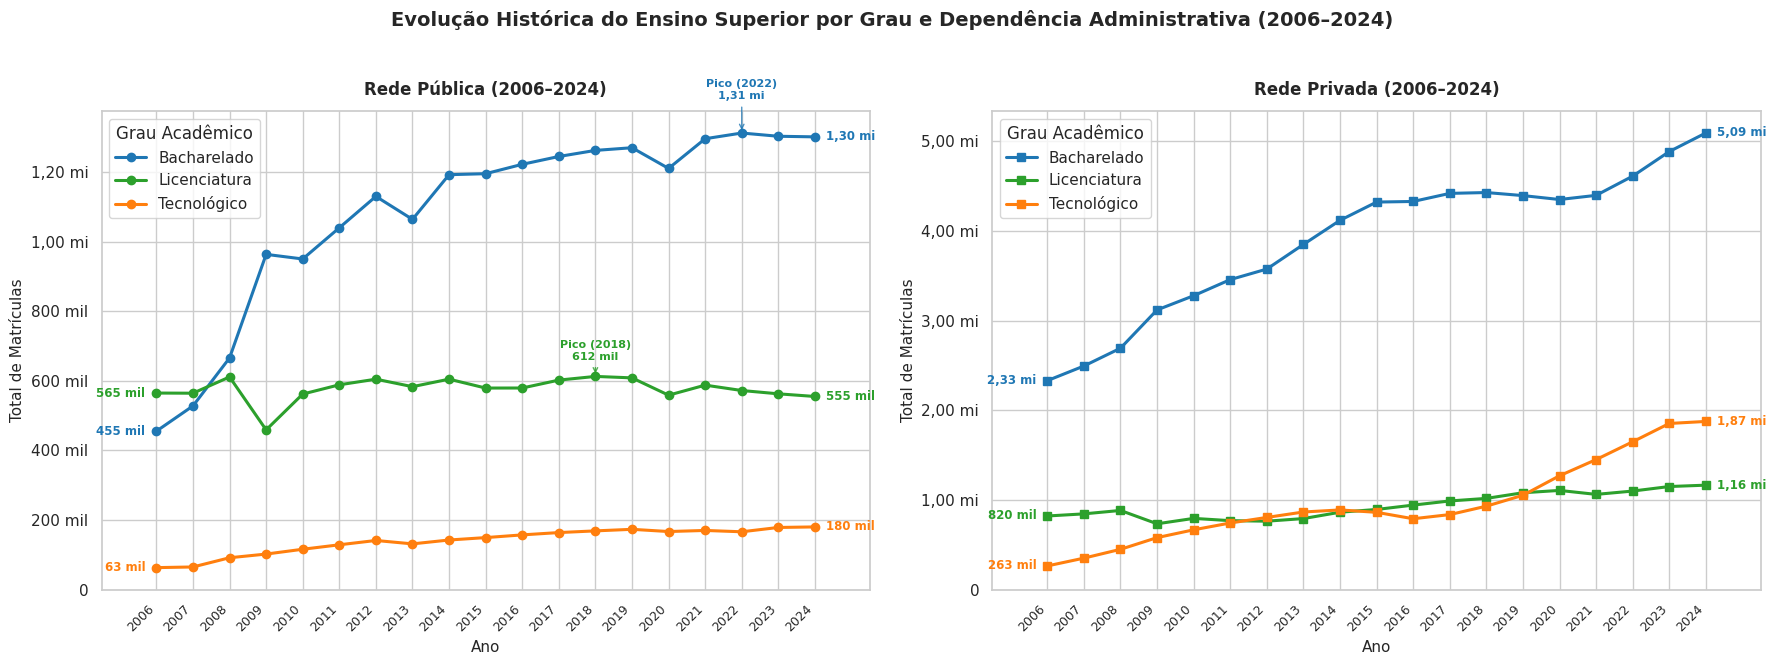

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

cores_graus = {
    "Bacharelado": "#1f77b4",
    "Licenciatura": "#2ca02c",
    "Tecnológico": "#ff7f0e"
}

def formata_br(val):
    if val >= 1e6:
        return f"{val*1e-6:.2f} mi".replace(".", ",")
    elif val > 0:
        return f"{val*1e-3:.0f} mil"
    return "0"

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

config_redes = [
    ("Pública", axes[0], "Rede Pública", "o"),
    ("Privada", axes[1], "Rede Privada", "s")
]

for rede, ax, titulo, marcador in config_redes:
    for grau, cor in cores_graus.items():
        serie = df_pivot_final[(rede, grau)]

        # Linha
        ax.plot(df_pivot_final.index, serie, marker=marcador, linewidth=2.2, label=grau, color=cor)

        # Início
        val_ini = serie.loc[ano_inicio]
        ax.annotate(formata_br(val_ini), xy=(ano_inicio, val_ini), xytext=(ano_inicio - 0.3, val_ini),
                    ha="right", va="center", fontsize=8.5, fontweight="bold", color=cor)

        # Fim
        val_f = serie.loc[ano_fim]
        ax.annotate(formata_br(val_f), xy=(ano_fim, val_f), xytext=(ano_fim + 0.3, val_f),
                    ha="left", va="center", fontsize=8.5, fontweight="bold", color=cor)

        # Pico
        ano_pico = serie.idxmax()
        if ano_pico not in [ano_inicio, ano_fim]:
            val_pico = serie.loc[ano_pico]
            ax.annotate(f"Pico ({ano_pico})\n{formata_br(val_pico)}", xy=(ano_pico, val_pico),
                        xytext=(ano_pico, val_pico * 1.07), ha="center", va="bottom",
                        fontsize=8, fontweight="bold", color=cor,
                        arrowprops=dict(arrowstyle="->", color=cor, lw=1, alpha=0.8))

    ax.set_title(f"{titulo} ({ano_inicio}–{ano_fim})", fontsize=12, weight="bold", pad=12)
    ax.set_ylabel("Total de Matrículas", fontsize=11)
    ax.set_xlabel("Ano", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: formata_br(x)))
    ax.set_ylim(bottom=0)
    ax.set_xlim(ano_inicio - 1.5, ano_fim + 1.5)
    ax.set_xticks(df_pivot_final.index)
    ax.set_xticklabels(df_pivot_final.index, rotation=45, ha="right", fontsize=9)
    ax.legend(title="Grau Acadêmico", frameon=True, loc="upper left")

plt.suptitle(f"Evolução Histórica do Ensino Superior por Grau e Dependência Administrativa ({ano_inicio}–{ano_fim})",
             fontsize=14, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

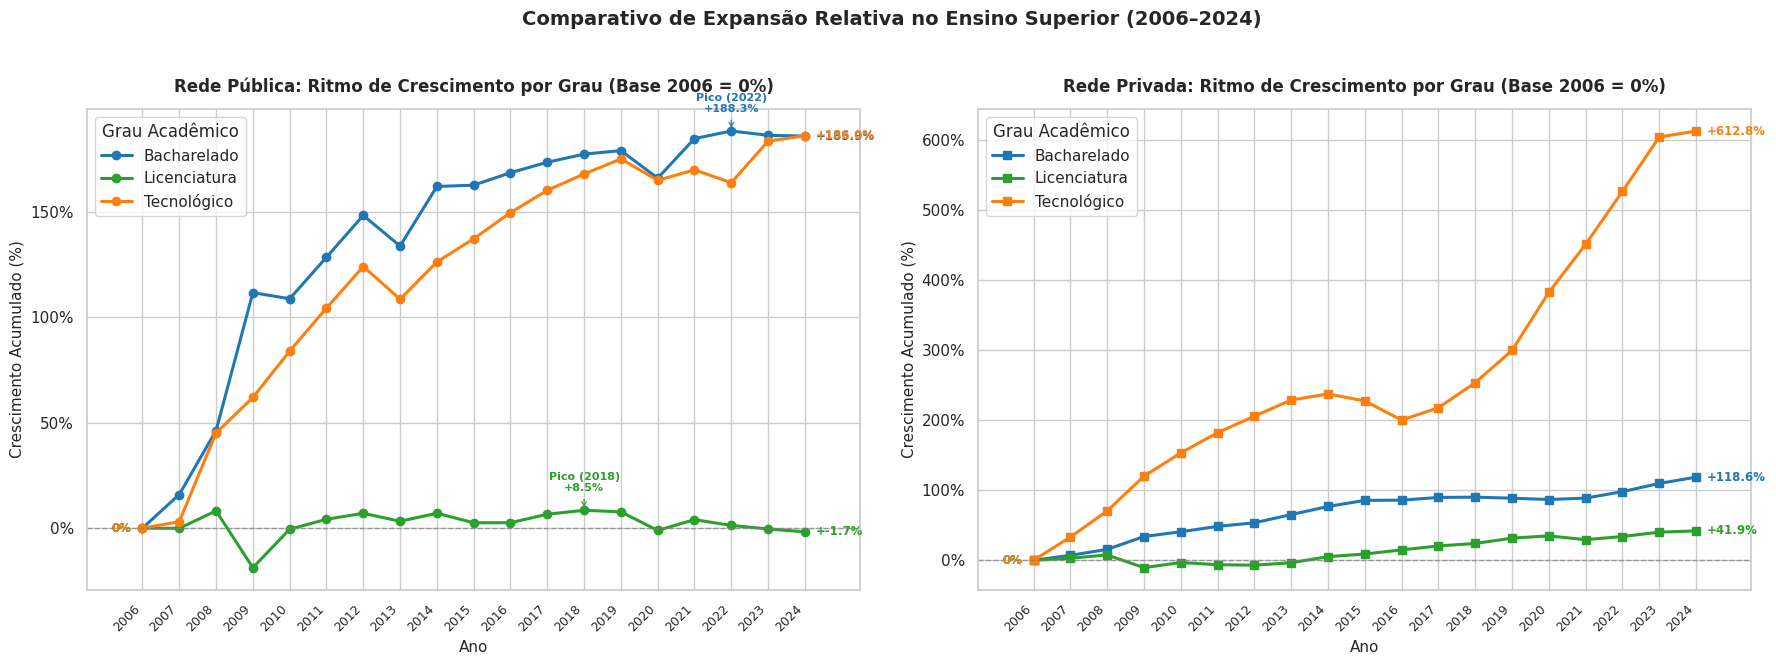

In [ ]:
# Cálculo do crescimento acumulado individual (Base ano_inicio = 0%)
df_acum_pub = pd.DataFrame(index=df_pivot_final.index)
df_acum_priv = pd.DataFrame(index=df_pivot_final.index)

for grau in cores_graus.keys():
    base_pub = df_pivot_final.loc[ano_inicio, ("Pública", grau)]
    base_priv = df_pivot_final.loc[ano_inicio, ("Privada", grau)]
    df_acum_pub[grau] = ((df_pivot_final[("Pública", grau)] - base_pub) / base_pub) * 100
    df_acum_priv[grau] = ((df_pivot_final[("Privada", grau)] - base_priv) / base_priv) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

config_acum = [
    (df_acum_pub, axes[0], f"Rede Pública: Ritmo de Crescimento por Grau (Base {ano_inicio} = 0%)", "o"),
    (df_acum_priv, axes[1], f"Rede Privada: Ritmo de Crescimento por Grau (Base {ano_inicio} = 0%)", "s")
]

for df_rede, ax, titulo, marcador in config_acum:
    for grau, cor in cores_graus.items():
        serie = df_rede[grau]

        ax.plot(df_rede.index, serie, marker=marcador, linewidth=2.2, label=grau, color=cor)

        # Início (0%)
        ax.annotate("0%", xy=(ano_inicio, 0), xytext=(ano_inicio - 0.3, 0),
                    ha="right", va="center", fontsize=8.5, fontweight="bold", color=cor)

        # Fim
        val_f = serie.loc[ano_fim]
        ax.annotate(f"+{val_f:.1f}%", xy=(ano_fim, val_f), xytext=(ano_fim + 0.3, val_f),
                    ha="left", va="center", fontsize=8.5, fontweight="bold", color=cor)

        # Pico
        ano_pico = serie.idxmax()
        if ano_pico not in [ano_inicio, ano_fim]:
            val_pico = serie.loc[ano_pico]
            ax.annotate(f"Pico ({ano_pico})\n+{val_pico:.1f}%", xy=(ano_pico, val_pico),
                        xytext=(ano_pico, val_pico + 8), ha="center", va="bottom",
                        fontsize=8, fontweight="bold", color=cor,
                        arrowprops=dict(arrowstyle="->", color=cor, lw=1, alpha=0.8))

    ax.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_title(titulo, fontsize=12, weight="bold", pad=12)
    ax.set_ylabel("Crescimento Acumulado (%)", fontsize=11)
    ax.set_xlabel("Ano", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.PercentFormatter())
    ax.set_xlim(ano_inicio - 1.5, ano_fim + 1.5)
    ax.set_xticks(df_pivot_final.index)
    ax.set_xticklabels(df_pivot_final.index, rotation=45, ha="right", fontsize=9)
    ax.legend(title="Grau Acadêmico", frameon=True, loc="upper left")

plt.suptitle(f"Comparativo de Expansão Relativa no Ensino Superior ({ano_inicio}–{ano_fim})",
             fontsize=14, weight="bold", y=1.02)
plt.tight_layout()
plt.show()